In [212]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split,KFold,cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score,confusion_matrix,ConfusionMatrixDisplay,precision_score,recall_score,f1_score
import matplotlib.pyplot as plt
import numpy as np

In [213]:
df = pd.read_csv(r'../data/insurance.csv')

In [214]:
df.sample(5)

,age,weight,height,income_lpa,smoker,city,occupation,insurance_premium_category
96,26,113.8,1.54,34.01,False,Delhi,private_job,Low
65,46,106.3,1.68,38.07,True,Jaipur,unemployed,High
98,27,101.1,1.82,28.30,False,Kolkata,business_owner,Low
39,51,100.6,1.68,11.99,True,Bangalore,unemployed,High
79,39,55.3,1.56,30.00,True,Indore,government_job,Low


In [215]:
df['occupation'].unique()

<StringArray>
[       'retired',     'freelancer',        'student', 'government_job',
 'business_owner',     'unemployed',    'private_job']
Length: 7, dtype: str

In [216]:
df_feat = df.copy()

In [217]:
# Feature 1: BMI
df_feat["bmi"] = df_feat["weight"] / (df_feat["height"] ** 2)

In [218]:
# Feature 2: Age Group
def age_group(age):
    if age < 25:
        return "young"
    elif age < 45:
        return "adult"
    elif age < 60:
        return "middle_aged"
    return "senior"

In [219]:
df_feat["age_group"] = df_feat["age"].apply(age_group)

In [220]:
# Feature 3: Lifestyle Risk
def lifestyle_risk(row):
    if row["smoker"] and row["bmi"] > 30:
        return "high"
    elif row["smoker"] or row["bmi"] > 27:
        return "medium"
    else:
        return "low"

In [221]:
df_feat["lifestyle_risk"] = df_feat.apply(lifestyle_risk, axis=1)

In [222]:
tier_1_cities = ["Mumbai", "Delhi", "Bangalore", "Chennai", "Kolkata", "Hyderabad", "Pune"]
tier_2_cities = [
    "Jaipur", "Chandigarh", "Indore", "Lucknow", "Patna", "Ranchi", "Visakhapatnam", "Coimbatore",
    "Bhopal", "Nagpur", "Vadodara", "Surat", "Rajkot", "Jodhpur", "Raipur", "Amritsar", "Varanasi",
    "Agra", "Dehradun", "Mysore", "Jabalpur", "Guwahati", "Thiruvananthapuram", "Ludhiana", "Nashik",
    "Allahabad", "Udaipur", "Aurangabad", "Hubli", "Belgaum", "Salem", "Vijayawada", "Tiruchirappalli",
    "Bhavnagar", "Gwalior", "Dhanbad", "Bareilly", "Aligarh", "Gaya", "Kozhikode", "Warangal",
    "Kolhapur", "Bilaspur", "Jalandhar", "Noida", "Guntur", "Asansol", "Siliguri"
]

In [223]:
# Feature 4: City Tier
def city_tier(city):
    if city in tier_1_cities:
        return 1
    elif city in tier_2_cities:
        return 2
    else:
        return 3

In [224]:
df_feat["city_tier"] = df_feat["city"].apply(city_tier)

In [225]:
df_feat.drop(columns=['age', 'weight', 'height', 'smoker', 'city'])[['income_lpa', 'occupation', 'bmi', 'age_group', 'lifestyle_risk', 'city_tier', 'insurance_premium_category']].sample(5)

,income_lpa,occupation,bmi,age_group,lifestyle_risk,city_tier,insurance_premium_category
35,43.280000,private_job,20.762578,middle_aged,medium,2,Medium
22,30.000000,government_job,31.771627,middle_aged,medium,2,Low
37,8.090000,freelancer,17.852127,adult,low,2,Medium
94,10.542289,government_job,33.266002,middle_aged,medium,1,Low
71,20.250000,unemployed,16.513537,adult,low,2,Low


In [226]:
# Select features and target
X = df_feat[["bmi", "age_group", "lifestyle_risk", "city_tier", "income_lpa", "occupation"]]
y = df_feat["insurance_premium_category"]

In [227]:
X

,bmi,age_group,lifestyle_risk,city_tier,income_lpa,occupation
0,49.227482,senior,medium,2,2.92000,retired
1,30.189017,adult,medium,1,34.28000,freelancer
2,21.118382,adult,low,2,36.64000,freelancer
3,45.535900,young,high,1,3.34000,student
4,24.296875,senior,medium,2,3.94000,retired
...,...,...,...,...,...,...
95,21.420747,adult,low,2,19.64000,business_owner
96,47.984483,adult,medium,1,34.01000,private_job
97,18.765432,middle_aged,low,1,44.86000,freelancer
98,30.521676,adult,medium,1,28.30000,business_owner


In [228]:
y

0       High
1        Low
2        Low
3     Medium
4       High
       ...  
95       Low
96       Low
97       Low
98       Low
99       Low
Name: insurance_premium_category, Length: 100, dtype: str

In [229]:
# Define categorical and numeric features
categorical_features = ["age_group", "lifestyle_risk", "occupation", "city_tier"]
numeric_features = ["bmi", "income_lpa"]

In [230]:
# Create column transformer for OHE
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

In [231]:
# Create a pipeline with preprocessing and random forest classifier
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    random_state=42
))
])

In [232]:
# Split data and train model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['bmi','age_group','lifestyle_risk','city_tier','income_lpa','occupation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remain

In [233]:
# Predict and evaluate
y_pred = pipeline.predict(X_test)
accuracy_score(y_test, y_pred)

0.75

In [234]:
X_test.sample(5)

,bmi,age_group,lifestyle_risk,city_tier,income_lpa,occupation
78,27.932798,middle_aged,medium,2,14.74,freelancer
52,47.344720,young,medium,2,2.96,student
81,31.866055,adult,high,2,22.19,freelancer
92,18.319942,adult,medium,2,30.00,government_job
65,37.662982,middle_aged,high,2,38.07,unemployed


In [235]:
from sklearn.model_selection import KFold, cross_validate
import numpy as np

# Define traditional K-Fold
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Perform cross-validation on training data
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=kf,
    scoring=scoring,
    return_train_score=True
)

# Display results
print("5-Fold Cross-Validation Results\n")

for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]

    print(f"{metric.capitalize()}:")
    print("Fold scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))
    print()

5-Fold Cross-Validation Results

Accuracy:
Fold scores: [0.75   0.75   0.75   0.75   0.5625]
Mean: 0.7125
Standard Deviation: 0.075

Precision:
Fold scores: [0.8333 0.8214 0.75   0.6944 0.4074]
Mean: 0.7013
Standard Deviation: 0.1553

Recall:
Fold scores: [0.7333 0.7333 0.7556 0.6944 0.5444]
Mean: 0.6922
Standard Deviation: 0.0765

F1:
Fold scores: [0.6819 0.6746 0.7475 0.6746 0.4646]
Mean: 0.6486
Standard Deviation: 0.096



In [236]:
train_scores = cv_results[f"train_{metric}"]

print("Training Mean:", round(train_scores.mean(), 4))
print("Validation Mean:", round(scores.mean(), 4))

Training Mean: 0.8496
Validation Mean: 0.6486


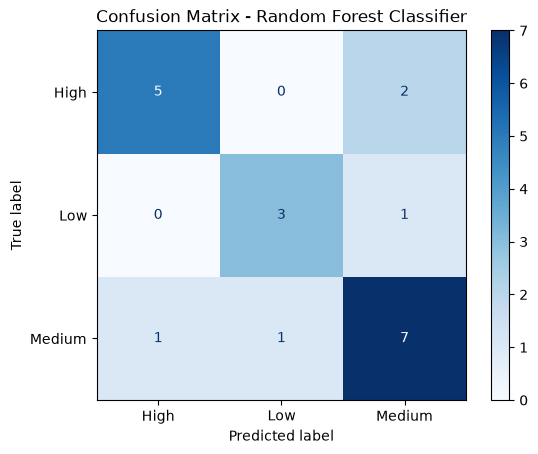

In [237]:

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=pipeline.classes_
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=pipeline.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Random Forest Classifier")
plt.show()


In [238]:

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Model Evaluation Metrics")
print("------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))


Model Evaluation Metrics
------------------------
Accuracy : 0.75
Precision: 0.7611
Recall   : 0.7474
F1-score : 0.752


In [239]:

# Create comparison table

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],

    "Cross Validation Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],

    "Test Performance": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print(comparison.round(4))


      Metric  Cross Validation Mean  Test Performance
0   Accuracy                 0.7125            0.7500
1  Precision                 0.7013            0.7611
2     Recall                 0.6922            0.7474
3   F1-score                 0.6486            0.7520


In [240]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.83      0.71      0.77         7
         Low       0.75      0.75      0.75         4
      Medium       0.70      0.78      0.74         9

    accuracy                           0.75        20
   macro avg       0.76      0.75      0.75        20
weighted avg       0.76      0.75      0.75        20

[[5 0 2]
 [0 3 1]
 [1 1 7]]


In [241]:
import pickle

# Save the trained pipeline using pickle
pickle_model_path = "model.pkl"
with open(pickle_model_path, "wb") as f:
    pickle.dump(pipeline, f)
